# 09 - regression

Process: minimize

$$
\mathrm{MSE}
=
\frac{1}{239}
\sum_{i=1}^{239}
\left(
C_i^{\mathrm{BS}}(r,\sigma)
-
C_i^{\mathrm{market}}
\right)^2
$$

We get $\tilde{r}, \tilde{\sigma}$.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from scipy.optimize import least_squares

In [4]:
data_path = Path("NDX_call_data.csv")

raw_df = pd.read_csv(
    data_path,
    index_col=0
)

print("Raw shape:", raw_df.shape)

raw_df.head()

Raw shape: (239, 7)


,spot_price,current_time,strike_price,best_bid,best_offer,ticker,market_price
0,14137.230469,0.989041,15700.0,493.5,528.5,NDX,511.00
1,14270.419922,0.986301,15700.0,530.6,557.9,NDX,544.25
2,14274.240234,0.983562,15700.0,515.7,544.3,NDX,530.00
3,14365.959961,0.980822,15700.0,552.5,592.4,NDX,572.45
4,14345.179688,0.978082,15700.0,539.3,575.6,NDX,557.45


In [6]:
# current_time in the CSV is time-to-maturity:
#tau = T - t

# Paper Eq. (5):
# C(S,t) = S*N(d1) - K*exp(-r*(T-t))*N(d2)

# Therefore we can directly use: tau = current_time

assert raw_df["strike_price"].nunique() == 1, \
    "Expected a single strike price."

K = float(
    raw_df["strike_price"].iloc[0]
)

S_real = raw_df["spot_price"].to_numpy(
    dtype=np.float64
)

tau_real = raw_df["current_time"].to_numpy(
    dtype=np.float64
)

V_market = raw_df["market_price"].to_numpy(
    dtype=np.float64
)

print("Number of observations:", len(V_market))
print("K:", K)

print(
    "S range:",
    S_real.min(),
    S_real.max()
)

print(
    "tau range:",
    tau_real.min(),
    tau_real.max()
)

print(
    "market price range:",
    V_market.min(),
    V_market.max()
)

Number of observations: 239
K: 15700.0
S range: 11127.5703125 16573.33984375
tau range: 0.0027397260273972 0.989041095890411
market price range: 0.2 1674.65


In [7]:
def black_scholes_call_price(
    S,
    tau,
    K,
    r,
    sigma,
    eps=1e-12
):
    """
    Black-Scholes European call price.

    Parameters
    S : array-like Spot price.

    tau : array-like Time-to-maturity, tau = T - t.

    K : float
        Strike price.

    r : float
        Risk-free interest rate.

    sigma : float
        Volatility.

    Returns
    call_price : np.ndarray
        Black-Scholes call prices.
    """

    S = np.asarray(
        S,
        dtype=np.float64
    )

    tau = np.asarray(
        tau,
        dtype=np.float64
    )

    # Numerical protection
    S_safe = np.maximum(
        S,
        eps
    )

    tau_safe = np.maximum(
        tau,
        eps
    )

    sigma_safe = max(
        float(sigma),
        eps
    )

    d1 = (
        np.log(S_safe / K)
        +
        (
            r
            + 0.5 * sigma_safe**2
        )
        * tau_safe
    ) / (
        sigma_safe
        * np.sqrt(tau_safe)
    )

    d2 = (
        d1
        -
        sigma_safe
        * np.sqrt(tau_safe)
    )

    call_price = (
        S_safe
        * norm.cdf(d1)
        -
        K
        * np.exp(
            -r * tau_safe
        )
        * norm.cdf(d2)
    )

    return call_price

In [9]:
# Cbs (real data in this case) - Cmarket
def regression_residuals(
    params,
    S,
    tau,
    V_market,
    K
):
    """
    Residuals for nonlinear least-squares regression.
    params[0] = r
    params[1] = sigma
    """

    r = params[0]
    sigma = params[1]

    V_bs = black_scholes_call_price(
        S=S,
        tau=tau,
        K=K,
        r=r,
        sigma=sigma
    )

    residuals = (
        V_bs
        -
        V_market
    )

    return residuals

In [12]:
# Same initial parameter values used in the inverse PINN
initial_guess = np.array(
    [
        0.10,   # r
        0.40    # sigma
    ],
    dtype=np.float64
)

# Positive bounds for r and sigma
lower_bounds = np.array(
    [
        1e-8,
        1e-8
    ]
)

upper_bounds = np.array(
    [
        1.0,
        3.0
    ]
)

regression_result = least_squares(
    fun=regression_residuals,

    x0=initial_guess,

    bounds=(
        lower_bounds,
        upper_bounds
    ),

    args=(
        S_real,
        tau_real,
        V_market,
        K
    ),

    max_nfev=10000
)

r_tilde = regression_result.x[0]
sigma_tilde = regression_result.x[1]

print(
    "Optimization success:",
    regression_result.success
)

print(
    "Message:",
    regression_result.message
)

print(
    "r_tilde:",
    r_tilde
)

print(
    "sigma_tilde:",
    sigma_tilde
)

Optimization success: True
Message: `ftol` termination condition is satisfied.
r_tilde: 0.010172999335777571
sigma_tilde: 0.2075829431955922


In [13]:
V_regression = black_scholes_call_price(
    S=S_real,
    tau=tau_real,
    K=K,
    r=r_tilde,
    sigma=sigma_tilde
)

regression_error = (
    V_regression
    -
    V_market
)

In [14]:
regression_mse = np.mean(
    regression_error**2
)

regression_rmse = np.sqrt(
    regression_mse
)

regression_mae = np.mean(
    np.abs(
        regression_error
    )
)

print(
    f"r_tilde       = {r_tilde:.10f}"
)

print(
    f"sigma_tilde   = {sigma_tilde:.10f}"
)

print(
    f"Regression MSE  = {regression_mse:.10f}"
)

print(
    f"Regression RMSE = {regression_rmse:.10f}"
)

print(
    f"Regression MAE  = {regression_mae:.10f}"
)

r_tilde       = 0.0101729993
sigma_tilde   = 0.2075829432
Regression MSE  = 6539.2966264031
Regression RMSE = 80.8659175822
Regression MAE  = 59.2223492083


In [15]:
regression_summary = pd.DataFrame(
    [
        {
            "n_data": len(V_market),
            "K": K,
            "r_tilde": r_tilde,
            "sigma_tilde": sigma_tilde,
            "regression_mse": regression_mse,
            "regression_rmse": regression_rmse,
            "regression_mae": regression_mae,
            "optimization_success": regression_result.success
        }
    ]
)

regression_summary.to_csv(
    "ndx_regression_full_data_results.csv",
    index=False
)

regression_summary

,n_data,K,r_tilde,sigma_tilde,regression_mse,regression_rmse,regression_mae,optimization_success
0,239,15700.0,0.010173,0.207583,6539.296626,80.865918,59.222349,True


### 1. compare r_pinn, sigma_pinn & r_tilda, sigma_tilde

In [23]:
parameter_comparison["r_abs_difference"] = np.abs(
    parameter_comparison["r_pinn"]
    -
    parameter_comparison["r_tilde"]
)

parameter_comparison["sigma_abs_difference"] = np.abs(
    parameter_comparison["sigma_pinn"]
    -
    parameter_comparison["sigma_tilde"]
)

parameter_comparison

,n_data,r_pinn,sigma_pinn,r_tilde,sigma_tilde,r_abs_difference,sigma_abs_difference
0,50,0.088845,0.117079,0.010173,0.207583,0.078672,0.090504
1,100,0.090087,0.118733,0.010173,0.207583,0.079914,0.088850
2,150,0.087372,0.117993,0.010173,0.207583,0.077199,0.089590
3,200,0.086219,0.123193,0.010173,0.207583,0.076046,0.084390


### Check regression converge to global min

In [24]:
initial_guesses = {
    "PINN-matched (0.10, 0.40)": np.array([0.10, 0.40]),
    "low (0.01, 0.10)":          np.array([0.01, 0.10]),
    "mid (0.05, 0.20)":          np.array([0.05, 0.20]),
    "high (0.20, 0.60)":         np.array([0.20, 0.60]),
}

multi_start_results = []

for label, x0 in initial_guesses.items():
    res = least_squares(
        fun=regression_residuals,
        x0=x0,
        bounds=(lower_bounds, upper_bounds),
        args=(S_real, tau_real, V_market, K),
        max_nfev=10000,
    )

    multi_start_results.append({
        "init_label": label,
        "r_init": x0[0],
        "sigma_init": x0[1],
        "r_tilde": res.x[0],
        "sigma_tilde": res.x[1],
        "cost": res.cost,          # 0.5 * sum(residuals**2)
        "success": res.success,
    })

multi_start_df = pd.DataFrame(multi_start_results)
multi_start_df

,init_label,r_init,sigma_init,r_tilde,sigma_tilde,cost,success
0,"PINN-matched (0.10, 0.40)",0.10,0.4,0.010173,0.207583,781445.946855,True
1,"low (0.01, 0.10)",0.01,0.1,0.010173,0.207583,781445.946830,True
2,"mid (0.05, 0.20)",0.05,0.2,0.010174,0.207582,781445.946943,True
3,"high (0.20, 0.60)",0.20,0.6,0.010174,0.207582,781445.946985,True


### 2. Eq5(r_pinn, sigma_pinn) vs Eq5(r_tilde, sigma_tilde) — visualization

In [26]:
def eq5_mse(r, sigma, S, tau, V_market, K):
    """
    Paper Eq. (5): plug (r, sigma) into the analytical BS formula and
    compute MSE against real market prices. Same formula used for both
    the PINN's estimated (r, sigma) and the regression's (r_tilde, sigma_tilde) 
    — isolates the quality of the parameter estimate itself
    """
    V_pred = black_scholes_call_price(S=S, tau=tau, K=K, r=r, sigma=sigma)
    return np.mean((V_pred - V_market) ** 2)


eq5_results = []

for _, row in parameter_comparison.iterrows():
    eq5_pinn = eq5_mse(
        r=row["r_pinn"], sigma=row["sigma_pinn"],
        S=S_real, tau=tau_real, V_market=V_market, K=K,
    )
    eq5_results.append({
        "n_data": row["n_data"],
        "source": "PINN",
        "r": row["r_pinn"],
        "sigma": row["sigma_pinn"],
        "eq5_mse": eq5_pinn,
    })

eq5_tilde = eq5_mse(
    r=r_tilde, sigma=sigma_tilde,
    S=S_real, tau=tau_real, V_market=V_market, K=K,
)
eq5_results.append({
    "n_data": "all (239)",
    "source": "Regression",
    "r": r_tilde,
    "sigma": sigma_tilde,
    "eq5_mse": eq5_tilde,
})

eq5_comparison = pd.DataFrame(eq5_results)
eq5_comparison

,n_data,source,r,sigma,eq5_mse
0,50.0,PINN,0.088845,0.117079,11775.497953
1,100.0,PINN,0.090087,0.118733,11737.185156
2,150.0,PINN,0.087372,0.117993,11653.326590
3,200.0,PINN,0.086219,0.123193,11051.384079
4,all (239),Regression,0.010173,0.207583,6539.296626


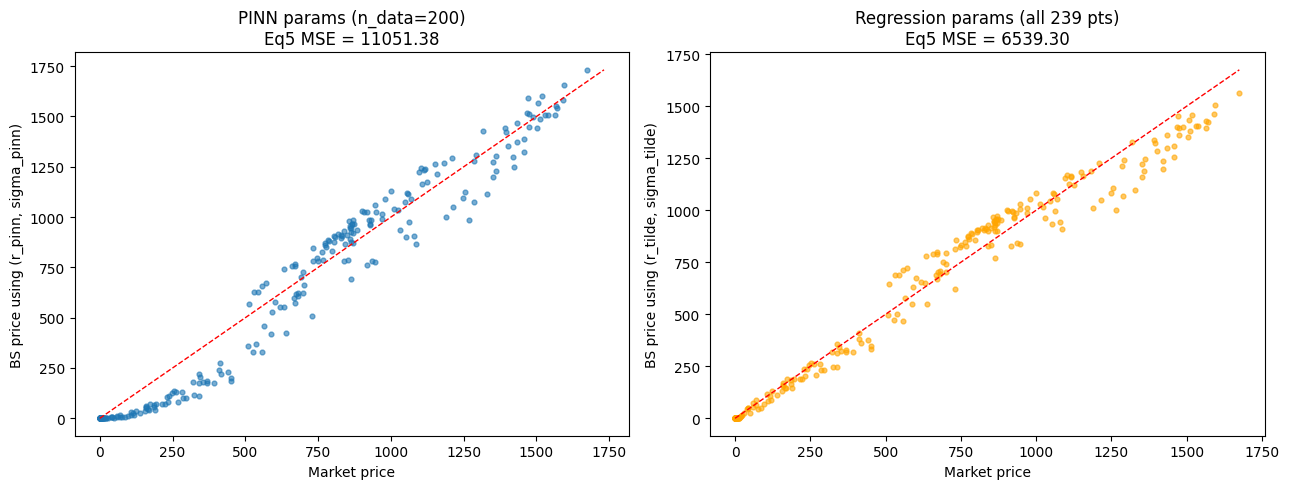

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

row_200 = parameter_comparison[parameter_comparison["n_data"] == 200].iloc[0]
V_pred_pinn_200 = black_scholes_call_price(
    S=S_real, tau=tau_real, K=K, r=row_200["r_pinn"], sigma=row_200["sigma_pinn"]
)

axes[0].scatter(V_market, V_pred_pinn_200, s=12, alpha=0.6)
lims = [min(V_market.min(), V_pred_pinn_200.min()), max(V_market.max(), V_pred_pinn_200.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Market price")
axes[0].set_ylabel("BS price using (r_pinn, sigma_pinn)")
eq5_200 = eq5_comparison.loc[eq5_comparison["n_data"] == 200, "eq5_mse"].values[0]
axes[0].set_title(f"PINN params (n_data=200)\nEq5 MSE = {eq5_200:.2f}")

V_pred_tilde = black_scholes_call_price(
    S=S_real, tau=tau_real, K=K, r=r_tilde, sigma=sigma_tilde
)

axes[1].scatter(V_market, V_pred_tilde, s=12, alpha=0.6, color="orange")
lims2 = [min(V_market.min(), V_pred_tilde.min()), max(V_market.max(), V_pred_tilde.max())]
axes[1].plot(lims2, lims2, "r--", linewidth=1)
axes[1].set_xlabel("Market price")
axes[1].set_ylabel("BS price using (r_tilde, sigma_tilde)")
axes[1].set_title(f"Regression params (all 239 pts)\nEq5 MSE = {eq5_tilde:.2f}")

plt.tight_layout()
plt.show()